In [ ]:
#LECCIÓN 2 : CLUSTERING JERÁRQUICO
#MARCELA GUERRERO HERNÁNDEZ

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os 

In [54]:
data0 = pd.read_excel('Amazon.xlsx')
data0.head()

# Guardar nombres y datos numéricos por separado
nombres_clientes = data0['Unnamed: 0']  # Guardar nombres
data = data0.drop('Unnamed: 0', axis=1)  # Quitar columna de nombres
data.head()

,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
0,205,3,345,235,24,23,26,21,17
1,9,15,315,33,25,4,42,215,28
2,17,26,285,3,43,27,41,26,33
3,135,5,355,295,18,23,39,195,17
4,3,45,48,39,34,46,225,34,43


In [10]:
from sklearn.preprocessing import normalize
data_scaled = normalize(data)
data_scaled

array([[0.43826336, 0.00641361, 0.73756517, 0.50239946, 0.05130888,
        0.04917101, 0.05558462, 0.04489527, 0.03634379],
       [0.02323527, 0.03872544, 0.81323434, 0.08519598, 0.06454241,
        0.01032679, 0.10843125, 0.55506471, 0.0722875 ],
       [0.05723452, 0.08753514, 0.95951982, 0.01010021, 0.14476966,
        0.09090188, 0.13803618, 0.08753514, 0.11110229],
       [0.25885639, 0.00958727, 0.68069644, 0.56564916, 0.03451419,
        0.04410146, 0.07478074, 0.37390368, 0.03259673],
       [0.01197502, 0.17962533, 0.19160036, 0.15567529, 0.13571692,
        0.18361701, 0.89812667, 0.13571692, 0.17164198],
       [0.14494006, 0.251738  , 0.60264551, 0.03661644, 0.03966781,
        0.02898801, 0.73995715, 0.03356507, 0.00457705],
       [0.04755854, 0.02481315, 0.98218723, 0.06823617, 0.07237169,
        0.09304932, 0.07857498, 0.05996511, 0.06410064],
       [0.13323393, 0.04304481, 0.06354234, 0.52268696, 0.05739308,
        0.04509456, 0.70716471, 0.44069685, 0.05944283],


In [11]:
data_scaled = pd.DataFrame(data_scaled, columns = data.columns)
data_scaled.head()

,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
0,0.438263,0.006414,0.737565,0.502399,0.051309,0.049171,0.055585,0.044895,0.036344
1,0.023235,0.038725,0.813234,0.085196,0.064542,0.010327,0.108431,0.555065,0.072287
2,0.057235,0.087535,0.959520,0.010100,0.144770,0.090902,0.138036,0.087535,0.111102
3,0.258856,0.009587,0.680696,0.565649,0.034514,0.044101,0.074781,0.373904,0.032597
4,0.011975,0.179625,0.191600,0.155675,0.135717,0.183617,0.898127,0.135717,0.171642


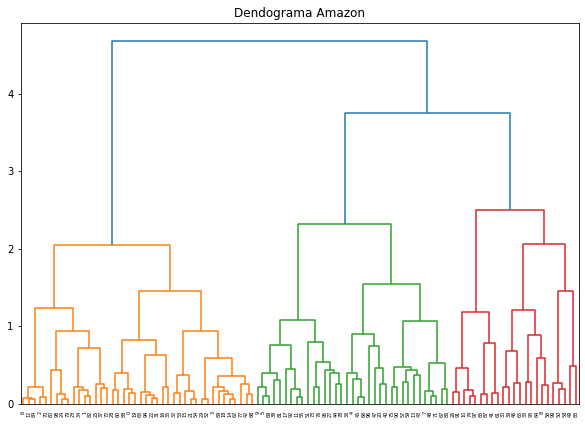

In [13]:
import scipy.cluster.hierarchy as shc
plt.figure(figsize=(10,7))
plt.title("Dendograma Amazon")
dend = shc.dendrogram(shc.linkage(data_scaled, method= 'ward'))

In [14]:
print(dend['color_list'])

['C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C1', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C3', 'C3', 'C3', 'C3', 'C3', 'C3', 'C3', 'C3', 'C3', 'C3', 'C3', 'C3', 'C3', 'C3', 'C3', 'C3', 'C3', 'C3', 'C3', 'C3', 'C3', 'C3', 'C0', 'C0']


In [19]:
colores_unicos = set(dend['color_list'])
colores_unicos


{'C0', 'C1', 'C2', 'C3'}

In [20]:
num_clusters_optimo = len(colores_unicos)-1
num_clusters_optimo

3

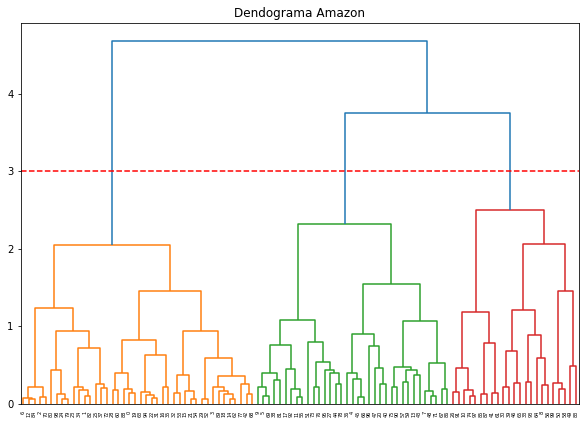

In [28]:
plt.figure(figsize=(10,7))
plt.title("Dendograma Amazon")
dend = shc.dendrogram(shc.linkage(data_scaled, method = 'ward'))
plt.axhline(y=3, color = 'r', linestyle = '--')

In [23]:
data

,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
0,205,3,345,235,24,23,26,21,17
1,9,15,315,33,25,4,42,215,28
2,17,26,285,3,43,27,41,26,33
3,135,5,355,295,18,23,39,195,17
4,3,45,48,39,34,46,225,34,43
...,...,...,...,...,...,...,...,...,...
95,3,8,32,25,7,21,42,17,1
96,305,25,46,24,33,28,355,26,45
97,1,14,26,25,24,27,42,185,23
98,155,11,335,34,26,29,42,215,27


In [30]:
from sklearn.cluster import AgglomerativeClustering
cluster = AgglomerativeClustering(n_clusters = 3, affinity='euclidean', linkage = 'ward')
grupos = cluster.fit_predict(data_scaled)
grupos

array([1, 1, 1, 1, 2, 2, 1, 2, 0, 2, 0, 2, 1, 2, 1, 1, 1, 2, 1, 1, 2, 1,
       1, 1, 1, 1, 0, 2, 1, 1, 0, 1, 1, 0, 1, 1, 2, 1, 2, 0, 2, 0, 1, 2,
       2, 2, 0, 2, 2, 0, 0, 2, 1, 1, 1, 2, 0, 2, 0, 2, 1, 0, 1, 1, 0, 0,
       2, 2, 1, 2, 1, 2, 1, 2, 0, 2, 2, 1, 2, 1, 1, 2, 1, 0, 1, 0, 2, 0,
       1, 1, 2, 0, 2, 0, 1, 2, 2, 0, 1, 0])

In [34]:
#SEPARACIÓN DE GRUPOS MEDIANTE PCA
campos = data_scaled.values
print(campos)

[[0.43826336 0.00641361 0.73756517 0.50239946 0.05130888 0.04917101
  0.05558462 0.04489527 0.03634379]
 [0.02323527 0.03872544 0.81323434 0.08519598 0.06454241 0.01032679
  0.10843125 0.55506471 0.0722875 ]
 [0.05723452 0.08753514 0.95951982 0.01010021 0.14476966 0.09090188
  0.13803618 0.08753514 0.11110229]
 [0.25885639 0.00958727 0.68069644 0.56564916 0.03451419 0.04410146
  0.07478074 0.37390368 0.03259673]
 [0.01197502 0.17962533 0.19160036 0.15567529 0.13571692 0.18361701
  0.89812667 0.13571692 0.17164198]
 [0.14494006 0.251738   0.60264551 0.03661644 0.03966781 0.02898801
  0.73995715 0.03356507 0.00457705]
 [0.04755854 0.02481315 0.98218723 0.06823617 0.07237169 0.09304932
  0.07857498 0.05996511 0.06410064]
 [0.13323393 0.04304481 0.06354234 0.52268696 0.05739308 0.04509456
  0.70716471 0.44069685 0.05944283]
 [0.73804829 0.0214705  0.12613916 0.63069581 0.09393342 0.00805144
  0.10198485 0.07246292 0.12882297]
 [0.00348086 0.30457545 0.56564012 0.00522129 0.06439595 0.05569

In [73]:
from sklearn import decomposition
pca = decomposition.PCA(n_components = 2)
pca.fit(campos)
campos = pca.transform(campos)
campos

array([[-0.39993219,  0.06035374],
       [-0.40829583, -0.06402268],
       [-0.49703182, -0.35955286],
       [-0.33996675,  0.18434501],
       [ 0.58207751, -0.38797653],
       [ 0.1723403 , -0.52962573],
       [-0.56528441, -0.33770585],
       [ 0.5335887 ,  0.06994712],
       [ 0.09981604,  0.47165743],
       [ 0.22195207, -0.56503313],
       [ 0.08274005,  0.39712712],
       [-0.00143465, -0.48936583],
       [-0.57292039, -0.35927774],
       [ 0.51350639,  0.01301312],
       [-0.35272162,  0.20639728],
       [-0.4688626 ,  0.0168001 ],
       [-0.25142488,  0.04599019],
       [-0.05456876, -0.22302796],
       [-0.36123131,  0.20553368],
       [-0.41087067,  0.02173183],
       [ 0.54207892, -0.03308916],
       [-0.5138909 , -0.0900875 ],
       [-0.4284552 , -0.0601418 ],
       [-0.42320562, -0.09945498],
       [-0.42610215,  0.06318626],
       [-0.10615885, -0.20376697],
       [ 0.19058214,  0.3966612 ],
       [-0.096838  , -0.33104612],
       [-0.51505714,

In [37]:
dataframe = pd.DataFrame(grupos, columns= ['grupo'])
dataframe

,grupo
0,1
1,1
2,1
3,1
4,2
...,...
95,2
96,2
97,0
98,1


In [38]:
dataframe2 = pd.concat([data, dataframe], axis= 1, join = 'inner')
dataframe2

,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas,grupo
0,205,3,345,235,24,23,26,21,17,1
1,9,15,315,33,25,4,42,215,28,1
2,17,26,285,3,43,27,41,26,33,1
3,135,5,355,295,18,23,39,195,17,1
4,3,45,48,39,34,46,225,34,43,2
...,...,...,...,...,...,...,...,...,...,...
95,3,8,32,25,7,21,42,17,1,2
96,305,25,46,24,33,28,355,26,45,2
97,1,14,26,25,24,27,42,185,23,0
98,155,11,335,34,26,29,42,215,27,1


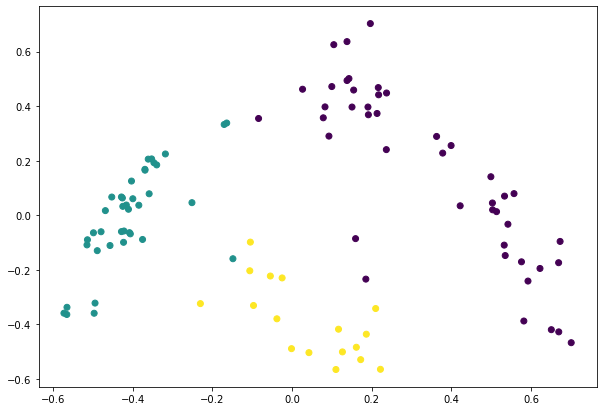

In [43]:
from sklearn.cluster import AgglomerativeClustering
cluster = AgglomerativeClustering(n_clusters = 3, affinity='euclidean', linkage = 'ward')
grupos = cluster.fit_predict(dataframe2)
grupos
plt.figure(figsize = (10,7))
plt.scatter(campos[:,0], campos[:,1], c = cluster.labels_)

In [46]:
#REGRESAMOS LOS NOMBRES PARA SABER DE QUIÉN SE TRATA CADA OBSERVACIÓN

resultado = data.copy()
resultado.insert(0, 'Cliente', nombres_clientes.values)
resultado['grupo'] = grupos
resultado

,Cliente,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas,grupo
0,Adam,205,3,345,235,24,23,26,21,17,1
1,Anna,9,15,315,33,25,4,42,215,28,1
2,Bernard,17,26,285,3,43,27,41,26,33,1
3,Edward,135,5,355,295,18,23,39,195,17,1
4,Emilia,3,45,48,39,34,46,225,34,43,0
...,...,...,...,...,...,...,...,...,...,...,...
95,Teofan,3,8,32,25,7,21,42,17,1,0
96,Teofil,305,25,46,24,33,28,355,26,45,0
97,Teofila,1,14,26,25,24,27,42,185,23,0
98,Teon,155,11,335,34,26,29,42,215,27,1


In [69]:
#IDENTIFICAMOS A NUSTRAS CLIENTAS OBJETIVO
from scipy.spatial.distance import cdist

X = data_scaled.values
D = cdist(X, X)  # matriz de distancias 100x100

objetivos = {'Salomé': 'salome', 'Stephanía': 'stephania', 'Lydia': 'lydia'}


#PARA SABER QUÉ PRODUCTOS RECOMENDARLES, BUSCAMOS LAS OBSERVACIONES QUE ESTÉN MÁS CERCA DE ELLAS DENTRO DEL CLUSTER
vecinos_dict = {}
for nombre, patron in objetivos.items():
    i = resultado.index[resultado['Cliente'].str.lower().str.contains(patron)][0]
    g = resultado.loc[i, 'grupo']

    # candidatos: mismo cluster, sin contarse a sí misma
    mismo = resultado.index[(resultado['grupo'] == g) & (resultado.index != i)]
    cercanos = mismo[np.argsort(D[i, mismo])][:3]
    vecinos_dict[nombre] = (i, list(cercanos))

    print(f"\n{nombre} (fila {i}, cluster {g})")
    for j in cercanos:
        print(f"  -> {resultado.loc[j,'Cliente']}  (distancia = {D[i,j]:.3f})")


Salomé (fila 81, cluster 2)
  -> Magdalyna  (distancia = 0.240)
  -> Fabian  (distancia = 0.261)
  -> Kalyna  (distancia = 0.264)

Stephanía (fila 89, cluster 1)
  -> Isidore  (distancia = 0.114)
  -> Markian  (distancia = 0.123)
  -> Judith  (distancia = 0.135)

Lydia (fila 54, cluster 1)
  -> Fedir  (distancia = 0.056)
  -> Joseph  (distancia = 0.125)
  -> Lourdes  (distancia = 0.253)


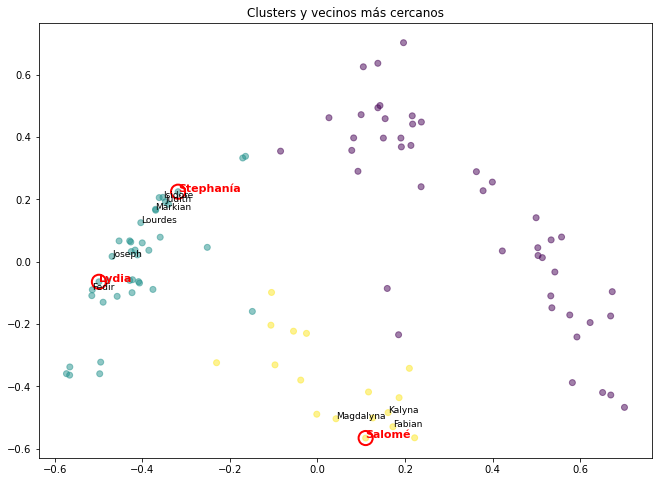

Recomendación para Salomé: A Salomé se le recomendarán los mismos productos que compró Magdalyna, Fabian y Kalyna.
Recomendación para Stephanía: A Stephanía se le recomendarán los mismos productos que compró Isidore, Markian y Judth.
Recomendación para Lydia: A Lydia se le recomendarán los mismos productos que compró Fedir, Joseph y Lourdes.
Aunque en el gráfico 2d pudiera parecer que hay otros puntos más cercanos a nuestros objetivos, se calcularon como los vecinos mas cercanos en distancia dentro de los clusters. Se ve así por la reducción de dimensiones de PCA


In [76]:
#FINALMENTE, GRAFICAMOS E IDENTIFICAMOS A LAS CLIENTAS A LAS QUE DAREMOS UNA RECOMENDACIÓN
#Y TAMBIÉN A LOS VECIMOS MÁS CERCANOS DE CADA UNA DE ELLAS
plt.figure(figsize=(11, 8))
plt.scatter(campos[:,0], campos[:,1], c=grupos, cmap='viridis', alpha=0.5)

for nombre, (i, cercanos) in vecinos_dict.items():
    plt.scatter(campos[i,0], campos[i,1], s=200, edgecolor='red', facecolor='none', linewidth=2)
    plt.annotate(nombre, campos[i], fontsize=11, fontweight='bold', color='red')
    for j in cercanos:
        plt.annotate(resultado.loc[j,'Cliente'], campos[j], fontsize=9)
plt.title("Clusters y vecinos más cercanos")
plt.show()

print("Recomendación para Salomé: A Salomé se le recomendarán los mismos productos que compró Magdalyna, Fabian y Kalyna.")
print("Recomendación para Stephanía: A Stephanía se le recomendarán los mismos productos que compró Isidore, Markian y Judth.")
print("Recomendación para Lydia: A Lydia se le recomendarán los mismos productos que compró Fedir, Joseph y Lourdes.")
print("Aunque en el gráfico 2d pudiera parecer que hay otros puntos más cercanos a nuestros objetivos, se calcularon como los vecinos mas cercanos en distancia dentro de los clusters. Se ve así por la reducción de dimensiones de PCA.")